<a href="https://colab.research.google.com/github/LinaMariaCastro/curso-ia-para-economia/blob/main/clases/4_Aprendizaje_no_supervisado/3_Taller_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)  
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)  
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# **Taller: Creación de un Índice de Clima de Inversión con Análisis de Componentes Principales (PCA)**

**IMPORTANTE**: Guarda una copia de este notebook en tu Google Drive o computador.

**Taller en parejas**

**Nombres estudiantes:**

-Nicolas Orduña
-

**Forma de entrega:**

- Nombrar el archivo de la siguiente forma:“Taller_PCA_apellidos.ipynb”.
- Suba el Jupyter Notebook a su cuenta en Github y envíe el link en el siguiente Forms: https://forms.cloud.microsoft/r/ZZX1AFUsPP.

**IMPORTANTE:** No se recibirán talleres en Google Colab, el notebook debe estar subido en Github.

**Plazo de entrega:**

21 de octubre de 2026, máximo a las 11:59 p.m. Tenga en cuenta que luego de esa hora el formulario en forms se cierra. El Jupupyter Notebook también debe quedar subido en Github antes de esa hora.

**Instrucciones Generales:**

Completa el código en las celdas marcadas con `### TU CÓDIGO AQUÍ ###`. Puedes añadir más celdas si lo requieres.

### Contexto

**Escenario:** Eres un científico de datos recién contratado como consultor experto por el **Ministerio de Comercio, Industria y Turismo (MinCIT)** de Colombia. Tu tarea principal es crear un **'Índice de Clima para la Inversión'** cuantitativo que permita clasificar y comparar el entorno competitivo de los países de América Latina y el Caribe. Este índice orientará las estrategias de integración regional y las políticas para atraer Inversión Extranjera Directa (IED).

**Objetivo:** Utilizando la base de datos de indicadores provista (preparada para este análisis) y la técnica de **Análisis de Componentes Principales (PCA)**, deberás extraer la "variable latente" que resume el clima de inversión, interpretar sus pesos económicos y presentar un ranking de países con recomendaciones ejecutivas.


## Ejercicio 1: Configuración Inicial, Carga y Exploración de Datos

1.1 Importa las librerías necesarias

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA


In [8]:
# Configuraciones de visualización
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

1.2 Carga el dataset "Indicators.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_indicators".

In [15]:
from google.colab import drive
drive.mount('/content/drive')

path = '/content/drive/MyDrive/Indicators.csv'
df_indicators = pd.read_csv(path)
df_indicators

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,CountryCode,IndicatorCode,Year,Value
0,CHL,NV.AGR.TOTL.ZS,2014,6.75
1,CHL,NE.TRD.GNFS.ZS,2014,74.31
2,CHL,NY.GDP.MKTP.KD.ZG,2014,7.65
3,CHL,FP.CPI.TOTL.ZG,2014,12.62
4,CHL,GC.DOD.TOTL.GD.ZS,2014,42.83
...,...,...,...,...
116,VEN,IC.LGL.DURS,2014,904.98
117,VEN,TX.VAL.MRCH.XD.WD,2014,"10,165,022,798.11"
118,VEN,TM.VAL.MRCH.XD.WD,2014,"8,144,071,082.17"
119,USA,NY.GDP.MKTP.KD.ZG,2014,2.50


In [16]:
# Debe ser (121, 4)
print("Dimensiones del DataFrame Indicators:")
print(df_indicators.shape)

Dimensiones del DataFrame Indicators:
(121, 4)


In [17]:
print("\nInformación general del DataFrame:")
df_indicators.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   CountryCode    121 non-null    object 
 1   IndicatorCode  121 non-null    object 
 2   Year           121 non-null    int64  
 3   Value          121 non-null    float64
dtypes: float64(1), int64(1), object(2)
memory usage: 3.9+ KB


1.3 Carga el dataset "Country.csv" que se encuentra en el repositorio del curso, carpeta "datasets". El dataframe debe llamarse "df_countries".

In [20]:
df_countries = pd.read_csv('/content/drive/MyDrive/Country-data.csv')
df_countries

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.20,10.00,7.58,44.90,1610,9.44,56.20,5.82,553
1,Albania,16.60,28.00,6.55,48.60,9930,4.49,76.30,1.65,4090
2,Algeria,27.30,38.40,4.17,31.40,12900,16.10,76.50,2.89,4460
3,Angola,119.00,62.30,2.85,42.90,5900,22.40,60.10,6.16,3530
4,Antigua and Barbuda,10.30,45.50,6.03,58.90,19100,1.44,76.80,2.13,12200
...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.20,46.60,5.25,52.70,2950,2.62,63.00,3.50,2970
163,Venezuela,17.10,28.50,4.91,17.60,16500,45.90,75.40,2.47,13500
164,Vietnam,23.30,72.00,6.84,80.20,4490,12.10,73.10,1.95,1310
165,Yemen,56.30,30.00,5.18,34.40,4480,23.60,67.50,4.67,1310


In [21]:
# Debe ser (14, 3)
print("Dimensiones del DataFrame Countries:")
print(df_countries.shape)

Dimensiones del DataFrame Countries:
(167, 10)


In [22]:
print("\nInformación general del DataFrame:")
df_countries.info()


Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


### Ejercicio 2: Selección y Preparación de Datos

Para el análisis del MinCIT, hemos preseleccionado un conjunto de variables clave.

2.1. Utiliza el diccionario para modificar los códigos de los indicadores por sus descripciones

In [23]:
nombre_indicadores = {
    'NV.AGR.TOTL.ZS': 'Agricultura (% del PIB)',
    'NE.TRD.GNFS.ZS': 'Comercio (% del PIB)',
    'NY.GDP.MKTP.KD.ZG': 'Crecimiento del PIB (%)',
    'FP.CPI.TOTL.ZG': 'Inflación (%)',
    'GC.DOD.TOTL.GD.ZS': 'Deuda del gob. central (% del PIB)',
    'SE.XPD.TOTL.GD.ZS': 'Gasto en educación (% del PIB)',
    'SH.XPD.CHEX.GD.ZS': 'Gasto en salud (% del PIB)',
    'IQ.CPA.BREG.XQ': 'Facilidad para hacer negocios',
    'IC.LGL.DURS': 'Días para cumplir contratos',
    'TX.VAL.MRCH.XD.WD': 'Exportaciones (US$)',
    'TM.VAL.MRCH.XD.WD': 'Importaciones (US$)'
}

In [24]:
df_indicators['IndicatorName'] = df_indicators['IndicatorCode'].map(nombre_indicadores)
df_indicators.head()



,CountryCode,IndicatorCode,Year,Value,IndicatorName
0,CHL,NV.AGR.TOTL.ZS,2014,6.75,Agricultura (% del PIB)
1,CHL,NE.TRD.GNFS.ZS,2014,74.31,Comercio (% del PIB)
2,CHL,NY.GDP.MKTP.KD.ZG,2014,7.65,Crecimiento del PIB (%)
3,CHL,FP.CPI.TOTL.ZG,2014,12.62,Inflación (%)
4,CHL,GC.DOD.TOTL.GD.ZS,2014,42.83,Deuda del gob. central (% del PIB)


2.2. Utiliza pivot table para crear un nuevo dataframe donde se encuentren los países como filas y los indicadores como columnas. Llama a este dataframe "df_pivot". No olvides colocar .reset_index() para que la columna de código de países quede como una columna y no como el índice.

In [25]:
### TU CÓDIGO AQUÍ ###
df_pivot = df_indicators.pivot_table(index='CountryCode', columns='IndicatorName', values='Value').reset_index()
df_pivot

IndicatorName,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61
5,CRI,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49
6,DEU,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ECU,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66
8,MEX,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52
9,PAN,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11


2.3. Crea el dataframe "df_final", realizando un merge entre "df_pivot" y "df_countries" con el fin de agregar el nombre de los países.

In [40]:
df_countries = pd.read_csv('/content/drive/MyDrive/Country-data.csv')
df_countries

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.20,10.00,7.58,44.90,1610,9.44,56.20,5.82,553
1,Albania,16.60,28.00,6.55,48.60,9930,4.49,76.30,1.65,4090
2,Algeria,27.30,38.40,4.17,31.40,12900,16.10,76.50,2.89,4460
3,Angola,119.00,62.30,2.85,42.90,5900,22.40,60.10,6.16,3530
4,Antigua and Barbuda,10.30,45.50,6.03,58.90,19100,1.44,76.80,2.13,12200
...,...,...,...,...,...,...,...,...,...,...
162,Vanuatu,29.20,46.60,5.25,52.70,2950,2.62,63.00,3.50,2970
163,Venezuela,17.10,28.50,4.91,17.60,16500,45.90,75.40,2.47,13500
164,Vietnam,23.30,72.00,6.84,80.20,4490,12.10,73.10,1.95,1310
165,Yemen,56.30,30.00,5.18,34.40,4480,23.60,67.50,4.67,1310


In [49]:
# Mapeo de códigos de país a nombres en español para los países de Latinoamérica y comparadores
mapeo_paises = {
    'ARG': 'Argentina',
    'BOL': 'Bolivia',
    'BRA': 'Brasil',
    'CHL': 'Chile',
    'COL': 'Colombia',
    'CRI': 'Costa Rica',
    'DEU': 'Alemania',
    'ECU': 'Ecuador',
    'MEX': 'México',
    'PAN': 'Panamá',
    'PER': 'Perú',
    'URY': 'Uruguay',
    'USA': 'Estados Unidos',
    'VEN': 'Venezuela'
}

df_final = df_pivot.copy()
df_final['CountryName'] = df_final['CountryCode'].map(mapeo_paises)

columnas = ['CountryCode', 'CountryName'] + [col for col in df_final.columns if col not in ['CountryCode', 'CountryName']]
df_final = df_final[columnas]
df_final

IndicatorName,CountryCode,CountryName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,ARG,Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
1,BOL,Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
2,BRA,Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
3,CHL,Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
4,COL,Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61
5,CRI,Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49
6,DEU,Alemania,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ECU,Ecuador,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66
8,MEX,México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52
9,PAN,Panamá,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11


2.4. Elimina las columnas "Region" y "CountryCode" y establece la columna 'ShortName' como el índice del dataframe

In [55]:
df_final.drop(columns=['CountryCode'], inplace=True)
df_final.set_index('CountryName', inplace=True)
df_final

IndicatorName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
CountryName,,,,,,,,,,,
Argentina,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28
Bolivia,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05
Brasil,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60
Chile,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62
Colombia,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61
Costa Rica,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49
Alemania,NaN,NaN,1.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ecuador,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66
México,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,NaN,"59,903,958,738.66",15.52


In [56]:
df_final = df_pivot.copy()
df_final['CountryName'] = df_final['CountryCode'].map(mapeo_paises)

### Ejercicio 3: Limpieza de Datos (Imputación de Valores Faltantes)

En la vida real de un economista, los datos tienen huecos. El PCA requiere bases completas. Usaremos una estrategia de imputación por la media para resolver los NaN.

3.1. Revisa cuántos valores faltantes hay en cada columna

In [59]:
missing_values = df_final.isnull().sum()
display(missing_values)

,0
IndicatorName,
CountryCode,0
Agricultura (% del PIB),4
Comercio (% del PIB),3
Crecimiento del PIB (%),0
Deuda del gob. central (% del PIB),4
Días para cumplir contratos,2
Exportaciones (US$),3
Facilidad para hacer negocios,5
Gasto en educación (% del PIB),3


3.2. Para cada columna, utiliza el promedio del resto de países de Latinoamérica para imputar los valores faltantes. El resultado debe quedar en un dataframe llamado "df_final_imputed". Al final revisa que no haya quedado ningún valor faltante en las columnas del dataframe.

In [62]:
df_final_imputed = df_final.copy()

columnas_numericas = df_final_imputed.select_dtypes(include=[np.number]).columns

for columna in columnas_numericas:
    promedio = df_final_imputed[columna].mean()
    df_final_imputed[columna].fillna(promedio, inplace=True)

df_final_imputed

/tmp/ipykernel_551/2540187698.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_final_imputed[columna].fillna(promedio, inplace=True)


IndicatorName,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),CountryName
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina
1,BOL,8.86,54.39,1.76,66.69,798.96,"39,036,984,373.93",3.96,5.37,5.05,"36,977,180,000.81",36.05,Bolivia
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile
4,COL,6.92,59.96,6.60,47.95,633.90,"56,527,087,039.04",3.96,6.34,6.30,"67,424,196,254.97",11.61,Colombia
5,CRI,8.11,70.86,5.88,58.75,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,Costa Rica
6,DEU,8.86,56.08,1.90,58.75,700.28,"56,527,087,039.04",3.96,5.17,6.24,"51,667,740,842.74",22.59,Alemania
7,ECU,10.88,54.23,1.82,63.47,739.26,"45,656,553,608.63",3.49,3.89,6.18,"39,525,318,329.77",28.66,Ecuador
8,MEX,9.27,49.22,4.85,52.55,614.33,"64,056,943,191.53",4.36,5.48,6.24,"59,903,958,738.66",15.52,México
9,PAN,5.80,56.08,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,Panamá


### Ejercicio 4: Matriz de Correlaciones y Estandarización de Variables

4.1. Grafica un mapa de calor para ver las correlaciones entre las variables.

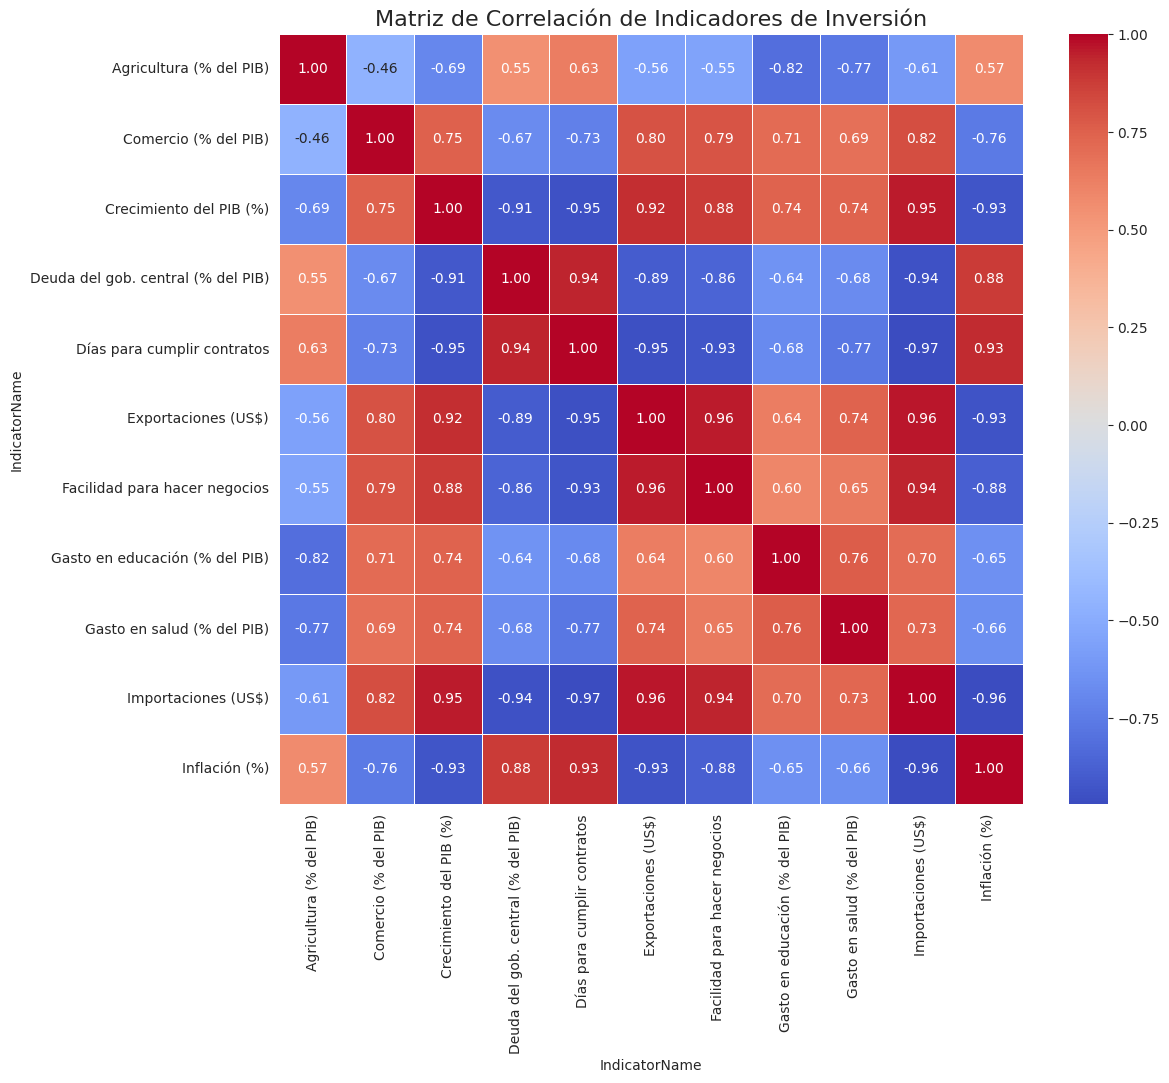

In [66]:
df_numerico = df_final_imputed.select_dtypes(include=[np.number])

matriz_correlacion = df_numerico.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_correlacion, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación de Indicadores de Inversión', fontsize=16)
plt.show()

4.2. Interpreta los resultados resaltando las correlaciones más relevantes.

El análisis del mapa de calor socioeconómico revela cuatro patrones clave: una fuerte integración comercial donde los grandes exportadores son también principales importadores; una relación inversa entre estabilidad macroeconómica y crecimiento, demostrando que la alta inflación ralentiza la economía; un compromiso conjunto con el capital humano, reflejado en la alta correlación entre el gasto en salud y educación; y un impacto negativo de la eficiencia institucional, donde los retrasos burocráticos para cumplir contratos reducen la facilidad para hacer negocios

4.3. Las exportaciones están en miles de millones de dólares y el crecimiento en porcentajes de un dígito. PCA busca varianzas, por lo que estandarizar (Media 0, Desviación 1) es un paso matemático obligatorio para no sesgar el modelo hacia las variables nominales grandes.  Estandariza todas las variables del dataframe y almacena el resultado en X_scaled.

In [67]:
x = df_final_imputed.select_dtypes(include=[np.number])
X_scaled = (x - x.mean()) / x.std()
X_scaled


IndicatorName,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%)
0,1.51,-2.24,-1.50,1.37,1.59,-1.62,-1.40,-2.71,-2.09,-1.62,1.61
1,-0.00,-0.16,-0.68,0.76,0.91,-0.78,0.00,0.19,-1.16,-0.71,1.00
2,2.07,0.39,-0.37,-0.15,0.38,-0.02,-0.31,-0.59,-0.91,-0.08,0.22
3,-1.11,1.73,1.51,-1.52,-1.51,1.51,1.52,1.18,1.98,1.39,-0.74
4,-1.02,0.37,1.12,-1.03,-0.61,0.00,0.00,1.14,0.05,0.76,-0.81
5,-0.40,1.40,0.85,0.00,-0.83,0.97,1.24,0.46,0.51,0.99,-1.04
6,-0.00,0.00,-0.63,0.00,0.00,0.00,0.00,0.00,0.00,-0.00,0.00
7,1.06,-0.17,-0.66,0.45,0.36,-0.48,-0.38,-1.24,-0.06,-0.58,0.45
8,0.22,-0.65,0.47,-0.59,-0.79,0.33,0.31,0.30,0.00,0.40,-0.52
9,-1.61,0.00,1.23,-1.46,-1.33,1.22,1.13,0.76,1.44,1.19,-1.07


### Ejercicio 5: Aplicación de PCA

Vamos a correr PCA para identificar el número de componentes. Buscamos capturar la mayor cantidad de información (varianza) con la menor cantidad de dimensiones.

5.1. Corre PCA sobre X_scaled y calcula la varianza acumulada. Almacénala en la variable "varianza_acumulada".

In [68]:
pca = PCA()
pca.fit(X_scaled)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
varianza_acumulada

array([0.80432386, 0.89486154, 0.93597174, 0.95991133, 0.97641891,
       0.9864744 , 0.99249496, 0.99665217, 0.99895635, 0.99961687,
       1.        ])

5.2. Similar a como lo vimos en clase, grafica la varianza explicada acumulada por componente.

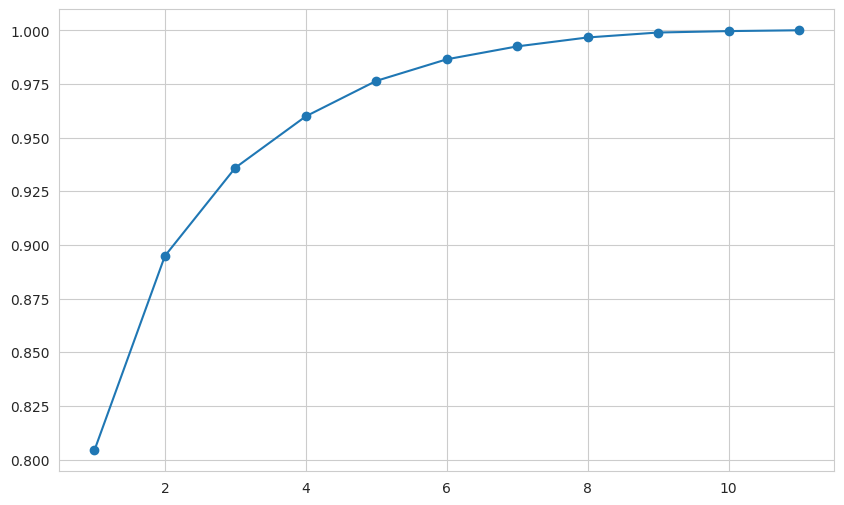

In [69]:
figu = plt.figure(figsize=(10, 6))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o', linestyle='-')


El gráfico de varianza acumulada revela que el primer componente principal (CP1) explica por sí solo el 80.43% de la varianza total de los datos, lo que evidencia que una única dimensión latente es capaz de capturar la gran mayoría de la información socioeconómica de los países. Al incorporar un segundo componente (CP2), la varianza explicada asciende al 89.49%, mostrando un retorno marginal decreciente que dibuja un claro punto de inflexión o "codo" después de la primera dimensión; por consiguiente, bajo criterios metodológicos estándar como el método del codo o la regla de retener al menos el 70-80% de la varianza, se justifica plenamente seleccionar únicamente el primer componente para estructurar un índice de clima de inversión unidimensional, simplificando la interpretación para el MinCIT sin comprometer la robustez analítica.

### Ejercicio 6: Interpretación Económica de los Componentes (Loadings)

Nos vamos a quedar con un solo componente. Vamor a analizar qué variables originales alimentan a este componente.

6.1. Corre nuevamente el PCA, pero ahora indicando que tenga en cuenta solo 1 componente. Almacena el modelo en "pca_final" y los resultados en "X_pca".

In [70]:
pca_final = PCA(n_components=1)
X_pca = pca_final.fit_transform(X_scaled)
X_pca = pd.DataFrame(X_pca, columns=['CP1'])
X_pca




,CP1
0,-5.72
1,-1.86
2,-1.20
3,4.72
4,2.05
5,2.65
6,-0.20
7,-1.73
8,0.94
9,3.75


6.2. Grafica el mapa de calor de los loadings como lo vimos en clase

<Axes: >

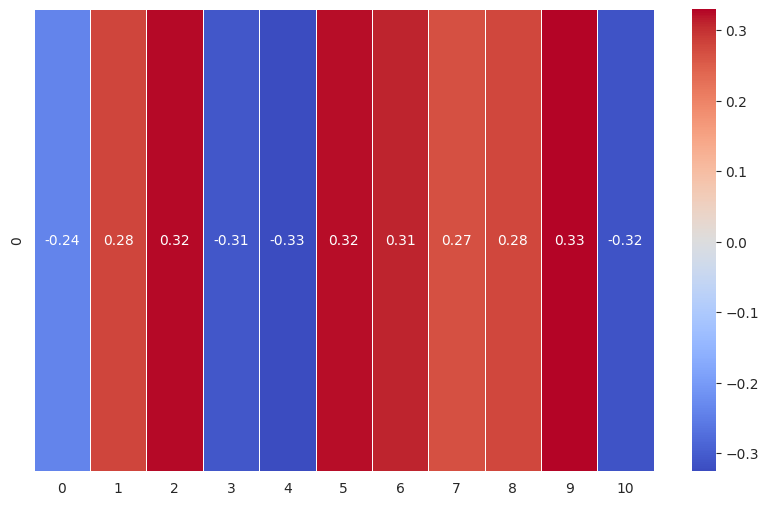

In [75]:
figure_loadings = plt.figure(figsize=(10, 6))
sns.heatmap(pca_final.components_, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

6.3. Realiza una interpretación de los loadings. ¿Cuáles variables tienen las cargas altas y positivas y cuáles las cargas altas y negativas? De acuerdo con este análisis, ¿consideras que efectivamente podemos utilizar el componente 1 como un índice del clima para la inversión en cada país de Latinoamérica? ¿por qué si o por qué no?

### Ejercicio 7: Creación del 'Índice de Clima para la Inversión'

Asignaremos el CP1 como nuestro 'Índice de Clima para la Inversión' y construiremos el ranking regional.

In [77]:
df_final['Indice_Inversion'] = X_pca['CP1'].values
df_final.head()

IndicatorName,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),CountryName,Indice_Inversion
0,ARG,11.73,32.43,-0.45,73.07,873.48,"20,153,725,105.95",2.19,2.38,4.09,"18,058,208,718.45",44.28,Argentina,-5.72
1,BOL,NaN,54.39,1.76,66.69,798.96,"39,036,984,373.93",NaN,5.37,5.05,"36,977,180,000.81",36.05,Bolivia,-1.86
2,BRA,12.79,60.18,2.59,57.20,741.68,"56,043,860,610.92",3.57,4.56,5.31,"50,026,448,161.33",25.60,Brasil,-1.20
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,4.72
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,2.05


7.1. Ordena el df_final por el índice de clima para la inversión de mayor a menor valor del índice.

In [78]:
df_final = df_final.sort_values(by='Indice_Inversion', ascending=False)
df_final.head()


IndicatorName,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),CountryName,Indice_Inversion
3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,4.72
9,PAN,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,Panamá,3.75
5,CRI,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,Costa Rica,2.65
4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,2.05
11,URY,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,Uruguay,1.05


7.2. Convierte 'ShortName' en una columna del dataframe.

In [80]:
df_final.reset_index(inplace=True)
df_final.head()
short_names = df_final['CountryName'].values
df_final.head()


IndicatorName,level_0,index,CountryCode,Agricultura (% del PIB),Comercio (% del PIB),Crecimiento del PIB (%),Deuda del gob. central (% del PIB),Días para cumplir contratos,Exportaciones (US$),Facilidad para hacer negocios,Gasto en educación (% del PIB),Gasto en salud (% del PIB),Importaciones (US$),Inflación (%),CountryName,Indice_Inversion
0,0,3,CHL,6.75,74.31,7.65,42.83,535.92,"90,542,560,043.59",5.88,6.38,8.29,"80,536,582,307.19",12.62,Chile,4.72
1,1,9,PAN,5.80,NaN,6.89,43.42,555.93,"83,978,447,805.32",5.40,5.95,7.72,"76,338,244,613.60",8.11,Panamá,3.75
2,2,5,CRI,8.11,70.86,5.88,NaN,610.31,"78,236,959,844.64",5.53,5.64,6.77,"72,324,083,969.39",8.49,Costa Rica,2.65
3,3,4,COL,6.92,59.96,6.60,47.95,633.90,NaN,NaN,6.34,6.30,"67,424,196,254.97",11.61,Colombia,2.05
4,4,11,URY,8.21,64.01,4.47,NaN,717.08,"63,598,148,937.21",NaN,5.63,6.65,"59,086,857,093.80",11.66,Uruguay,1.05


7.3. Utiliza un barplot para mostrar los resultados del Índice de Clima para la Inversión. En el eje y deben ir los países y en el eje X el puntaje del índice. No olvides colocar título al gráfico y a los ejes.

/tmp/ipykernel_551/2968747497.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Indice_Inversion', y='CountryName', data=df_final, palette='viridis')


<Axes: xlabel='Indice_Inversion', ylabel='CountryName'>

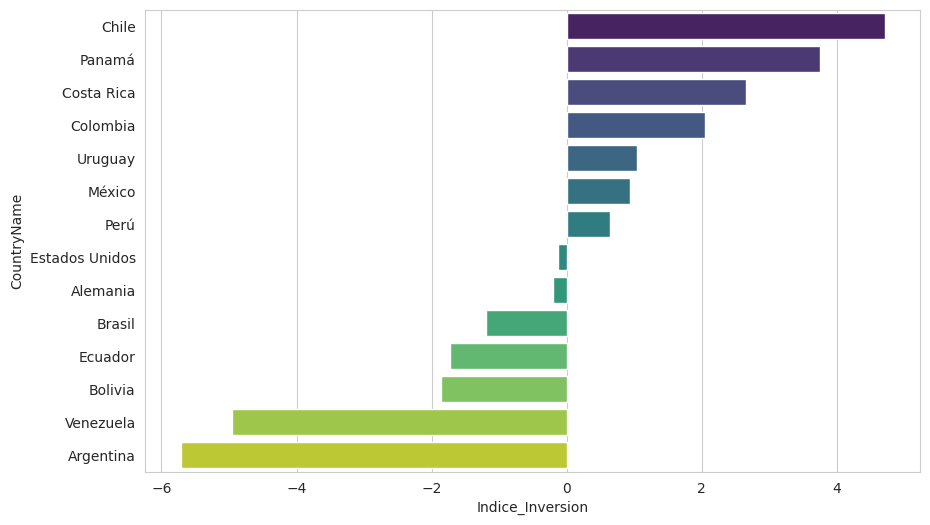

In [81]:
df_final.head()
plt.figure(figsize=(10, 6))
sns.barplot(x='Indice_Inversion', y='CountryName', data=df_final, palette='viridis')




 sitúa a Colombia en el cuarto lugar de la región con un puntaje positivo de 2.05, consolidándolo como un destino atractivo pero con desafíos importantes frente a sus principales competidores directos por la atracción de capital extranjero: Chile (4.72), Panamá (3.75) y Costa Rica (2.65). Estos países lideran el ranking regional gracias a una ventaja competitiva multidimensional explicada por variables macroeconómicas e institucionales clave: Chile sobresale con el mayor crecimiento económico de la muestra (7.65%), un robusto gasto en salud y educación, y una excelente eficiencia regulatoria reflejada en la menor cantidad de días para hacer cumplir contratos (535 días) y un alto nivel de facilidades institucionales; Panamá capitaliza su bajo nivel de inflación (8.11%) y su alto dinamismo en comercio exterior; y Costa Rica muestra una gran inserción comercial global acompañada de excelentes indicadores sociales. En contraste, aunque Colombia exhibe un saludable crecimiento del PIB (6.60%) y una sólida inversión social en educación (6.34% del PIB), se encuentra rezagada frente a estos líderes debido a una mayor presión inflacionaria (11.61%), mayores tiempos de resolución judicial para cumplir contratos (633.90 días) y un nivel de endeudamiento gubernamental superior (47.95% del PIB), lo que urge al ministerio a priorizar políticas orientadas a la desregulación, la seguridad jurídica de las transacciones y la estabilización de los costos de producción para cerrar la brecha competitiva con el bloque líder de la región.